# MicroCT step 0b — scan positions by cross-correlation

Scan 93 is an **11 x 11 raster** (121 = 11^2 positions, 4 um nominal step,
+/- 2 um random jitter per the logbook), not the random walk `BoneNano_nfp`'s
scan 80 was. That matters for the chained registration below: within a row,
consecutive frames are ~4 um apart and correlate well; at every row end the
stage flies back across the whole row, and that jump is the weak point in a
chain. This notebook adds a check for exactly that (cell "row-end jumps")
that `BoneNano_nfp`'s own notebook does not need.

Appends `/exchange/shifts` to `data_nfp.h5`, the last thing `step0.py` needs.

Shifts are **(row, col) in pixels at this bin**, built exactly as the
phascade `bone_nano_holotomo` NFP notebook builds them:

1. divide by `pref` to strip the probe envelope, **then** by the frame mean
   to strip the static weak-CA pattern -- without the second division the
   correlation locks onto the weak CA, which does not move;
2. `phase_corr` between CONSECUTIVE frames;
3. integrate from a **mid-scan anchor**, giving `pos[anchor] - pos[k]`,
   which is the engine's sign;
4. centre with `centered_full`.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('../../src'))
import numpy as np, cupy as cp, h5py
import matplotlib.pyplot as plt

from holotomocupy.config import parse_args_coded_step0
CFG = parse_args_coded_step0('config_step0.conf')   # paths from the config
H5 = CFG.in_file
RAW_DIR = CFG.raw_nfp

with h5py.File(H5, 'r') as f:
    pdata = np.asarray(f['/exchange/pdata'], 'float32')
    pref  = np.asarray(f['/exchange/pref'],  'float32')
NPOS, nz, n = pdata.shape
print(f'{NPOS} positions, {nz} x {n}')

121 positions, 2048 x 2048


## Positions: chained registration from a mid-scan anchor

anchor=60  span(px) row 1003.0 col 986.0  max|shift| 501.5


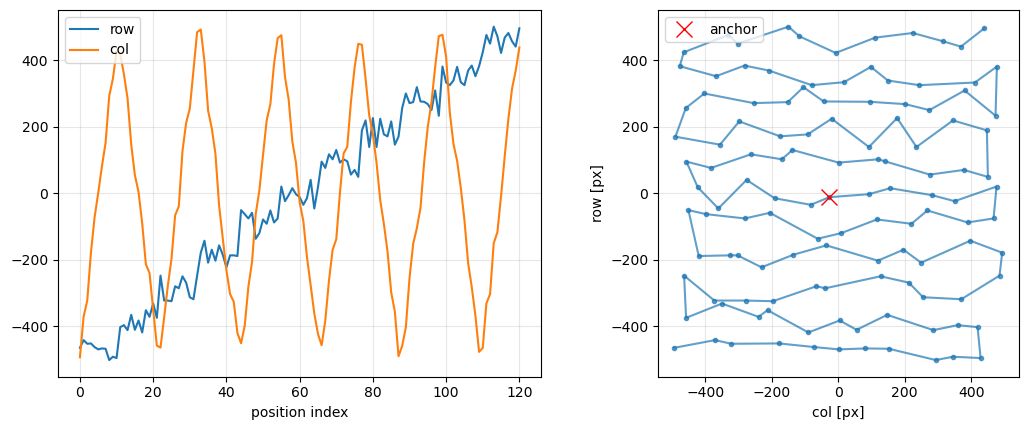

In [2]:
def phase_corr(a, b):
    # Integer-pixel displacement of b relative to a.
    # Matches phascade.preprocess.phase_corr exactly.
    A, B = cp.fft.fft2(cp.asarray(a)), cp.fft.fft2(cp.asarray(b))
    cc = cp.fft.fftshift(cp.fft.ifft2(A * cp.conj(B)).real)
    i = cp.unravel_index(cp.argmax(cc), cc.shape)
    return np.array([int(i[0]) - cc.shape[0] // 2,
                     int(i[1]) - cc.shape[1] // 2], 'float32')

def integrate_shifts_from_anchor(rel, anchor):
    # out[k] = pos[anchor] - pos[k], from consecutive relative shifts.
    rel = np.asarray(rel)
    out = np.zeros_like(rel)
    for k in range(anchor):
        out[k] = np.sum(rel[k:anchor], axis=0)
    out[anchor] = 0
    for k in range(anchor + 1, len(rel)):
        out[k] = np.sum(-rel[anchor:k], axis=0)
    return out

def centered_full(po):
    return po - (po.max(0) + po.min(0)) / 2

# TWO divisions, both needed -- this is the step that decides whether the
# registration sees the strong CA at all:
#   / pref        strips the probe envelope (per pixel)
#   / rd.mean(0)  strips the STATIC weak-CA pattern, which does not move and
#                 would otherwise dominate the correlation peak and pull
#                 every measured shift toward zero
rd = pdata / (pref[None] + 1e-6)
rd = rd / (rd.mean(0)[None] + 1e-6)

step = np.zeros((NPOS, 2), 'float32')
for k in range(NPOS - 1):
    step[k] = phase_corr(rd[k], rd[k + 1])

ipos = NPOS // 2                       # mid-scan anchor
shifts = integrate_shifts_from_anchor(step, ipos)
shifts = centered_full(shifts)

print(f'anchor={ipos}  span(px) row {np.ptp(shifts[:,0]):.1f} '
      f'col {np.ptp(shifts[:,1]):.1f}  max|shift| {np.abs(shifts).max():.1f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].plot(shifts[:, 0], label='row'); ax[0].plot(shifts[:, 1], label='col')
ax[0].set_xlabel('position index'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(shifts[:, 1], shifts[:, 0], 'o-', ms=3, alpha=.7)
ax[1].plot(shifts[ipos, 1], shifts[ipos, 0], 'rx', ms=12, label='anchor')
ax[1].set_xlabel('col [px]'); ax[1].set_ylabel('row [px]')
ax[1].set_aspect('equal'); ax[1].grid(alpha=.3); ax[1].legend()
plt.tight_layout(); plt.show()

## Diagnostic: are the row-end jumps the weak point in the chain?

An 11 x 11 raster has 10 row-end transitions (`k % 11 == 10`) where the stage
flies back across a whole row -- a much bigger single step than the ~4 um
within-row moves. Print those steps separately: if they are wildly larger or
less consistent than the within-row steps, the chain may be mis-registering
exactly there, which then propagates into every position on the far side of
that jump.

within-row steps:  median 101.54 px   max 169.86 px
row-end steps:      median 94.93 px   max 148.05 px   (n=10)


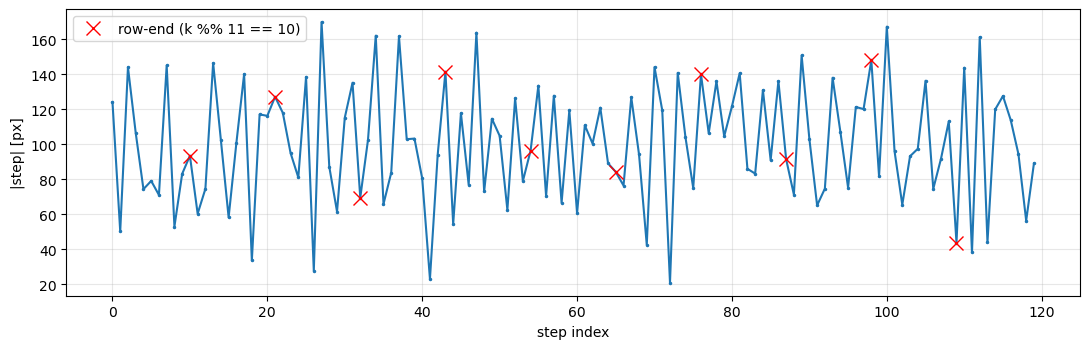

In [3]:
step_mag = np.linalg.norm(step[:-1], axis=1)   # one fewer than NPOS
row_end  = np.array([k % 11 == 10 for k in range(len(step_mag))])

print(f'within-row steps:  median {np.median(step_mag[~row_end]):.2f} px   '
      f'max {step_mag[~row_end].max():.2f} px')
print(f'row-end steps:      median {np.median(step_mag[row_end]):.2f} px   '
      f'max {step_mag[row_end].max():.2f} px   (n={row_end.sum()})')

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(step_mag, '.-', ms=3)
ax.plot(np.where(row_end)[0], step_mag[row_end], 'rx', ms=10, label='row-end (k %% 11 == 10)')
ax.set_xlabel('step index'); ax.set_ylabel('|step| [px]'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Diagnostic: does a direct registration agree with the chained one?

Chaining through neighbours and registering straight against the anchor
are independent routes to the same number. They agree only if the
correlation is actually locking onto the strong CA.

chained vs direct: mean |d| 1.368 px, max 4.500 px
Expect ~1 px. Tens of px means the registration is locking onto something other than the strong CA -- check that the /rd.mean(0) division above really removed the static weak-CA pattern.


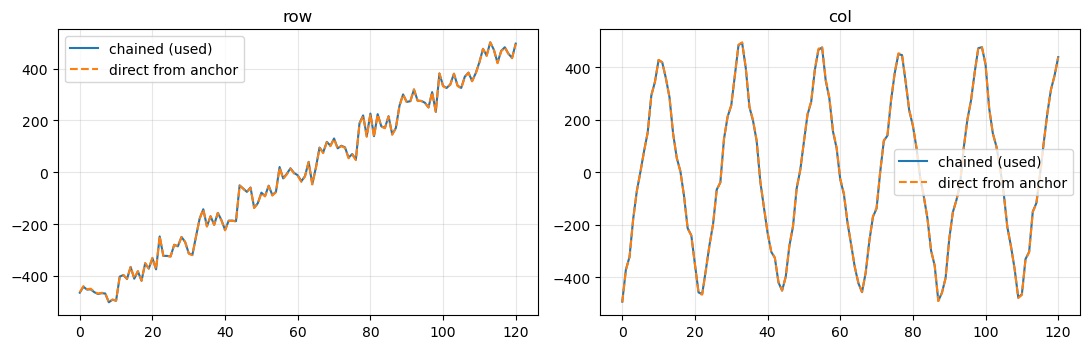

In [4]:
# Independent route: register every frame DIRECTLY against the anchor instead
# of chaining through its neighbours. phase_corr(rd[ipos], rd[k]) is the
# displacement of k relative to the anchor, and the chained result is
# pos[anchor] - pos[k], so the two differ by a sign.
direct = -np.stack([phase_corr(rd[ipos], rd[k]) for k in range(NPOS)])
direct = centered_full(direct)

err = np.abs(direct - shifts)
print(f'chained vs direct: mean |d| {err.mean():.3f} px, max {err.max():.3f} px')
print('Expect ~1 px. Tens of px means the registration is locking onto '
      'something other than the strong CA -- check that the /rd.mean(0) '
      'division above really removed the static weak-CA pattern.')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for d, lab in enumerate(('row', 'col')):
    ax[d].plot(shifts[:, d], label='chained (used)')
    ax[d].plot(direct[:, d], '--', label='direct from anchor')
    ax[d].set_title(lab); ax[d].legend(); ax[d].grid(alpha=.3)
plt.tight_layout(); plt.show()

## Diagnostic: do the measured shifts agree with the recorded motor positions?

New relative to `BoneNano_nfp`, worth the effort here because the motors
(`nf_x`, `nf_y` in `scan-0093.h5`) recorded this raster. This is an
INDEPENDENT, absolute check: it never touches `phase_corr` and would not
inherit a sign error or a bad division the same way the "direct" check above
could (that check reuses the same `rd` and the same `phase_corr`).

Expect the row and column slopes to agree with each other to a few percent
(the stage is isotropic) and the residual to be small, flat, and consistent
with the logbook's +/- 2 um jitter -- NOT growing over the scan or spiking at
the row-end indices from the previous cell.

Do not replace the measured shifts with this fit. The motors do not know the
per-position jitter; this is a check, not a source.

row: 23.229 px/um   residual rms 26.586 px   max |res| 47.917 px
col: 23.066 px/um   residual rms 24.145 px   max |res| 45.874 px
slope ratio row/col = 1.007  (expect close to 1.0, isotropic stage)


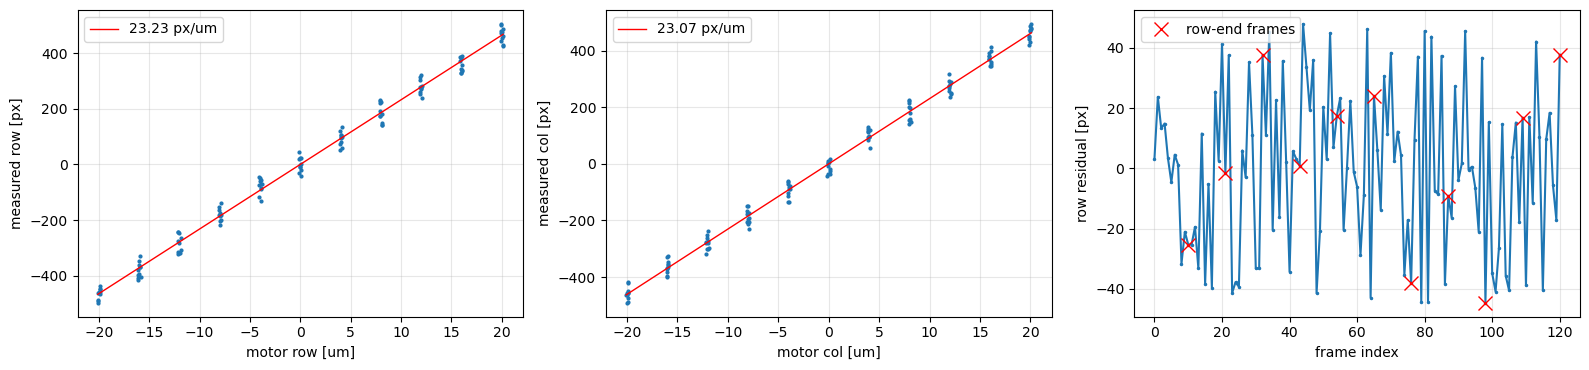

In [5]:
with h5py.File(f'{RAW_DIR}/scan-0093.h5', 'r') as f:
    nf_x = np.asarray(f['/entry/instrument/nf_x/value'], 'float64')
    nf_y = np.asarray(f['/entry/instrument/nf_y/value'], 'float64')
assert len(nf_x) == NPOS, f'{len(nf_x)} motor values vs {NPOS} frames'

nf = np.stack([nf_y, nf_x], axis=1) * 1e3      # mm -> um, (row, col) to match shifts' axis order
nf = nf - nf.mean(0)
sh = shifts - shifts.mean(0)

slopes = np.zeros(2)
for i, lbl in enumerate(('row', 'col')):
    k = float((nf[:, i] @ sh[:, i]) / (nf[:, i] @ nf[:, i]))
    res = sh[:, i] - k * nf[:, i]
    slopes[i] = k
    print(f'{lbl}: {k:.3f} px/um   residual rms {res.std():.3f} px   max |res| {np.abs(res).max():.3f} px')
print(f'slope ratio row/col = {slopes[0]/slopes[1]:.3f}  (expect close to 1.0, isotropic stage)')

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for i, lbl in enumerate(('row', 'col')):
    ax[i].plot(nf[:, i], sh[:, i], '.', ms=4)
    xx = np.array([nf[:, i].min(), nf[:, i].max()])
    ax[i].plot(xx, slopes[i] * xx, 'r-', lw=1, label=f'{slopes[i]:.2f} px/um')
    ax[i].set_xlabel(f'motor {lbl} [um]'); ax[i].set_ylabel(f'measured {lbl} [px]')
    ax[i].legend(); ax[i].grid(alpha=.3)
res_row = sh[:, 0] - slopes[0] * nf[:, 0]
ax[2].plot(res_row, '.-', ms=3)
row_end_idx = [k for k in range(NPOS) if k % 11 == 10]
ax[2].plot(row_end_idx, res_row[row_end_idx], 'rx', ms=10, label='row-end frames')
ax[2].set_xlabel('frame index'); ax[2].set_ylabel('row residual [px]'); ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

## Diagnostic: is the scan big enough to need the plane we configured?

`npsiz`/`npsi` must clear `nz`/`n` plus twice the largest shift plus a margin,
or `step0.py`'s FOV filter silently throws positions away. This prints what
the config should say -- **check this BEFORE running `step0.py`**: the
provisional `npsi=8192` in `config_step0.conf` was a placeholder, not a
measurement.

In [6]:
mx = np.abs(shifts).max(0)
need = np.array([nz, n]) + 2 * np.ceil(mx) + 2 * 16
print(f'max |shift|  rows {mx[0]:.0f}  cols {mx[1]:.0f}')
print(f'minimum npsiz x npsi = {need[0]:.0f} x {need[1]:.0f}')
print(f'rounded up to a power of two: '
      f'{1 << int(np.ceil(np.log2(need[0])))} x {1 << int(np.ceil(np.log2(need[1])))}')
print(f'config_step0.conf currently has npsiz={CFG.npsiz} npsi={CFG.npsi} -- '
      + ('OK' if CFG.npsiz >= need[0] and CFG.npsi >= need[1] else
         'TOO SMALL, raise npsiz/npsi to the value above before running step0.py'))

max |shift|  rows 502  cols 493
minimum npsiz x npsi = 3084 x 3066
rounded up to a power of two: 4096 x 4096
config_step0.conf currently has npsiz=8192 npsi=8192 -- OK


## Diagnostic: is the scan-92 probe reference still valid?

In [7]:
# The weak CA is supposed to have stayed put since scan 92. Check it rather
# than assume it -- BoneNano_nfp's own README documents exactly this
# assumption failing between an earlier pair of scans (CA1 moved between
# scan 69 and scan 80), which is why that scan was abandoned.
def hp(img, s=0.02):
    f = cp.fft.fftfreq(img.shape[0]).astype('float32')
    fx, fy = cp.meshgrid(f, f)
    lp = cp.exp(-(fx ** 2 + fy ** 2) / (2 * s ** 2)).astype('float32')
    return (cp.asarray(img) / (cp.fft.ifft2(cp.fft.fft2(cp.asarray(img)) * lp).real + 1e-3)).astype('float32')

static93 = pdata.mean(0)      # strong CA's walk averages out; weak CA + beam survive
shift92v93 = phase_corr(cp.asnumpy(hp(pref)), cp.asnumpy(hp(static93)))
print(f'scan 92 vs scan 93 mean, high-pass registered: row {shift92v93[0]:.2f}  col {shift92v93[1]:.2f} px')
if np.abs(shift92v93).max() >= 1:
    print('  -> NON-NEGLIGIBLE. See BoneNano_nfp/README.md ("CA1 moved between scan 69 and scan 80")'
          ' for what that cost there.')
else:
    print('  -> negligible, consistent with the weak CA (and beam) being unchanged since scan 92.')

scan 92 vs scan 93 mean, high-pass registered: row 0.00  col 0.00 px
  -> negligible, consistent with the weak CA (and beam) being unchanged since scan 92.


## Append to `data_nfp.h5`

In [8]:
with h5py.File(H5, 'a') as f:
    if '/exchange/shifts' in f:
        del f['/exchange/shifts']
    f.create_dataset('/exchange/shifts', data=shifts.astype('float32'))
print('wrote /exchange/shifts', shifts.shape)
print('Next:  mpirun -np <ngpus> python step0.py config_step0.conf')

wrote /exchange/shifts (121, 2)
Next:  mpirun -np <ngpus> python step0.py config_step0.conf
